### Bài thực hành số 2. Sử dụng thư viện ML: Phân tích và Dự đoán Dữ liệu NYC Taxi
Bài thực hành này hướng dẫn từng bước quy trình Học máy (Machine Learning) trên PySpark qua bài toán thực tế với dữ liệu NYC Taxi Trips. Quá trình bao gồm 3 nhóm bài toán:
1. Gom cụm (KMeans): Phân nhóm các chuyến đi theo khoảng cách và giá cước.
2. Phân loại (Logistic Regression & Decision Tree): Dự đoán chuyến đi có nhận tiền thưởng cao (Tip cao) hay không.
3. Pipeline & Model Persistence: Tự động hóa quy trình sản xuất và lưu trữ mô hình.

### Kết quả chính — toàn bộ dữ liệu sạch
Đọc **5.515.455** dòng từ Lab1, giữ **4.523.472** chuyến thẻ hợp lệ; nhãn tip cao chiếm **75,016%**. Các mô hình được so trên cùng **905.414** chuyến test; tham số cải tiến được chọn bằng validation.

| Mô hình | ROC-AUC | PR-AUC | Accuracy |
|---|---:|---:|---:|
| LR cơ sở | 0,584662 | 0,799646 | 75,4765% |
| DT depth=5 | 0,589745 | 0,804432 | 75,5764% |
| DT depth=10 | 0,600730 | 0,809035 | 75,5805% |
| LR cải tiến | 0,608202 | 0,811161 | 75,6168% |

KMeans chưa chuẩn hóa: Silhouette k=3 **0,838328**, k=4 **0,819545**. Sau chuẩn hóa, k=3 vẫn cao hơn k=4 trong không gian mới.

Baseline luôn đoán lớp phổ biến đạt accuracy **75,1035%**. LR cải tiến chỉ hơn khoảng **0,51 điểm phần trăm** và recall lớp tip thấp là **3,1236%**. Vì vậy điểm xếp hạng tăng, nhưng mô hình vẫn nhận diện yếu nhóm tip thấp.


## Lời giải — 9 bài tập
Chạy Lab1 trước. Notebook so sánh các mô hình trên **cùng tập test**, fit các bước học thống kê bằng train.
Có thể đặt `ML_FRACTION=0.02` để chạy thử với mẫu cố định; các kết quả khi đó chỉ mô tả mẫu.
Feature không chứa `tip_amount`, `total_amount` hoặc biến suy ra từ tiền tip để tránh lộ nhãn.
Nguồn: [NYC TLC](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page), [MLlib](https://spark.apache.org/docs/4.0.2/ml-guide.html).

In [1]:
import os, math
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == 'loi_giai': ROOT = ROOT.parent
os.chdir(ROOT)
import sys
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.master('local[2]').appName('NYC_Taxi_ML_Solutions')
    .config('spark.driver.memory','3g').config('spark.sql.shuffle.partitions','8')
    .config('spark.sql.session.timeZone','America/New_York').config('spark.ui.enabled','false').config('spark.ui.showConsoleProgress','false')
    .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
# 1.0 = toàn bộ dữ liệu. Giảm để thử nhanh, luôn ghi rõ số mẫu trong output.
ML_FRACTION = float(os.environ.get('ML_FRACTION','1.0'))
assert 0 < ML_FRACTION <= 1

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/29 21:43:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


1 - Tải & Nạp dữ liệu Parquet đã làm sạch ở bài thực hành trước

In [2]:
path = './nyc_data/yellow_tripdata_2023-01-02-parquet'
if not Path(path).exists():
    raise FileNotFoundError('Hãy chạy Lab1 trước để tạo Parquet sạch: ' + path)
df_raw_full = spark.read.parquet(path)
df_raw = df_raw_full if ML_FRACTION == 1 else df_raw_full.sample(False, ML_FRACTION, seed=42)
print(f'Tỷ lệ mẫu từ dữ liệu Lab1: {ML_FRACTION:.1%}; số bản ghi sử dụng: {df_raw.count():,}')
df_raw.printSchema()
df_raw.select('tpep_pickup_datetime','passenger_count','trip_distance','payment_type','fare_amount','tip_amount').show(5)

Tỷ lệ mẫu từ dữ liệu Lab1: 100.0%; số bản ghi sử dụng: 5,515,455
root
 |-- VendorID: long (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: long (nullable = true)
 |-- DOLocationID: long (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- speed_mph: d

+--------------------+---------------+-------------+------------+-----------+----------+
|tpep_pickup_datetime|passenger_count|trip_distance|payment_type|fare_amount|tip_amount|
+--------------------+---------------+-------------+------------+-----------+----------+
| 2023-01-01 00:32:10|            1.0|         0.97|           2|        9.3|       0.0|
| 2023-01-01 00:55:08|            1.0|          1.1|           1|        7.9|       4.0|
| 2023-01-01 00:25:04|            1.0|         2.51|           1|       14.9|      15.0|
| 2023-01-01 00:10:29|            1.0|         1.43|           1|       11.4|      3.28|
| 2023-01-01 00:50:34|            1.0|         1.84|           1|       12.8|      10.0|
+--------------------+---------------+-------------+------------+-----------+----------+
only showing top 5 rows


2 - Khám phá & Làm sạch dữ liệu (EDA & Data Cleaning)

In [3]:
from pyspark.sql.functions import col, hour, count, avg, round, when

# 1. Kiểm tra dữ liệu nhiễu/ngoại lệ trong dữ liệu
# Trong thực tế: Chuyến đi có khoảng cách <= 0, cước phí <= 0, hoặc giá trị NULL là dữ liệu rác.
df_clean = df_raw.filter(
    (col("trip_distance") > 0) & 
    (col("trip_distance") < 100) &          # Loại bỏ các chuyến đi ảo > 100 miles
    (col("fare_amount") > 0) & 
    (col("fare_amount") < 500) &            # Loại bỏ cước phí bất thường > 500$
    (col("passenger_count").isNotNull()) & 
    (col("passenger_count") > 0)
)

# 2. Tạo cột mới 'pickup_hour' trích xuất giờ từ 'tpep_pickup_datetime'
df_clean = df_clean.withColumn("pickup_hour", hour(col("tpep_pickup_datetime")))

# 3. Lưu ý thực tế: Dữ liệu taxi NYC chỉ ghi nhận tiền Tip chính xác đối với hình thức thanh toán thẻ Thẻ Tín Dụng (payment_type = 1).
# Với thanh toán Tiền Mặt (payment_type = 2), lái xe tự nhận cash và hệ thống mặc định ghi tip = $0.
df_credit = df_clean.filter(col("payment_type") == 1)

print(f"Số lượng bản ghi sau khi làm sạch: {df_credit.count():,}")

# Thống kê giá cước và tiền tip trung bình theo khung giờ trong ngày
df_credit.groupBy("pickup_hour").agg(
    count("*").alias("so_chuyen"),
    round(avg("fare_amount"), 2).alias("cuoc_tb"),
    round(avg("tip_amount"), 2).alias("tip_tb")
).orderBy("pickup_hour").show(10)

Số lượng bản ghi sau khi làm sạch: 4,523,472


+-----------+---------+-------+------+
|pickup_hour|so_chuyen|cuoc_tb|tip_tb|
+-----------+---------+-------+------+
|          0|   124874|  18.87|  4.15|
|          1|    86216|   16.8|  3.74|
|          2|    59334|   15.9|  3.51|
|          3|    37087|  16.83|  3.67|
|          4|    21598|  22.44|  4.68|
|          5|    21838|  27.84|  5.54|
|          6|    59273|  22.11|  4.46|
|          7|   125019|  18.42|  3.91|
|          8|   173709|  17.07|  3.72|
|          9|   192089|  17.38|  3.88|
+-----------+---------+-------+------+
only showing top 10 rows


Bài tập 1: Thống kê xem có bao nhiêu chuyến đi trong tập dữ liệu df_clean có hình thức thanh toán bằng Tiền mặt (payment_type == 2).
Tìm khoảng cách chuyến đi lớn nhất (max) và nhỏ nhất (min) trong tập df_clean.

In [4]:
df_clean.agg(
    F.sum(F.when(F.col('payment_type') == 2,1).otherwise(0)).alias('cash_trip_count'),
    F.min('trip_distance').alias('min_trip_distance_miles'),
    F.max('trip_distance').alias('max_trip_distance_miles')
).show(truncate=False)

+---------------+-----------------------+-----------------------+
|cash_trip_count|min_trip_distance_miles|max_trip_distance_miles|
+---------------+-----------------------+-----------------------+
|943043         |0.01                   |28.63                  |
+---------------+-----------------------+-----------------------+



3 - Tiền xử lý & Chọn thuộc tính (Feature Engineering & Selection)

In [5]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
# Nhãn: lớn hơn 20% (không gồm đúng 20%). Chỉ dùng thanh toán thẻ.
df_labeled = (df_credit.filter(F.col('tip_amount').isNotNull() & (F.col('tip_amount') >= 0))
    .withColumn('high_tip', F.when(F.col('tip_amount')/F.col('fare_amount') > 0.20,1).otherwise(0))
    .na.fill(1,subset=['RatecodeID'])
    .dropna(subset=['pickup_hour','PULocationID','DOLocationID']))
feature_cols = ['trip_distance','fare_amount','passenger_count','pickup_hour','PULocationID','DOLocationID']
# Chia dữ liệu thô trước khi FIT scaler để tránh rò rỉ thống kê tập test.
raw_train, raw_test = df_labeled.randomSplit([0.8,0.2],seed=42)
raw_train = raw_train.cache(); raw_test = raw_test.cache()
print('Train:', raw_train.count(), '| Test:', raw_test.count())

def prepare_features(columns):
    assembler = VectorAssembler(inputCols=columns,outputCol='raw_features')
    scaler = StandardScaler(inputCol='raw_features',outputCol='features',withStd=True,withMean=True)
    model = scaler.fit(assembler.transform(raw_train))
    return assembler, model, model.transform(assembler.transform(raw_train)), model.transform(assembler.transform(raw_test))

assembler, scaler_model, train_data, test_data = prepare_features(feature_cols)
train_data.select('raw_features','features','high_tip').show(3,truncate=False)

Train: 3618058 | Test: 905414


+------------------------------+------------------------------------------------------------------------------------------------------------------------+--------+
|raw_features                  |features                                                                                                                |high_tip|
+------------------------------+------------------------------------------------------------------------------------------------------------------------+--------+
|[2.1,11.4,1.0,0.0,238.0,262.0]|[-0.29147584745167754,-0.43480533016541495,-0.4243563436238901,-2.477739717835006,1.1362853771967307,1.4105174944182086]|1       |
|[2.1,14.2,6.0,0.0,170.0,113.0]|[-0.29147584745167754,-0.25360697661911763,5.265814752591392,-2.477739717835006,0.06180248567553787,-0.7469351363952192]|0       |
|[1.4,9.3,1.0,0.0,211.0,209.0] |[-0.4608938500750113,-0.5707040953251379,-0.4243563436238901,-2.477739717835006,0.7096524643868453,0.6431014579543718]  |1       |
+---------------------

Bài tập 2: Hãy tính tỷ lệ phần trăm các chuyến đi đạt nhãn high_tip = 1 so với high_tip = 0 trong tập dữ liệu để kiểm tra xem tập dữ liệu có bị mất cân bằng nhãn (imbalanced) hay không.
Thêm cột RatecodeID vào danh sách feature_cols và xử lý các giá trị Null của cột này (nếu có) bằng phương thức .na.fill(1).

In [6]:
label_counts = df_labeled.groupBy('high_tip').count()
n_labeled = df_labeled.count()
(label_counts.withColumn('percentage',F.round(F.col('count')/F.lit(n_labeled)*100,3))
    .orderBy('high_tip').show())
counts = {int(r.high_tip): r['count'] for r in label_counts.collect()}
if len(counts) < 2:
    raise ValueError('Cần đủ cả hai nhãn để huấn luyện và đánh giá AUC.')
imbalance_ratio = max(counts.values())/min(counts.values())
print(f'Tỷ số lớp lớn / lớp nhỏ: {imbalance_ratio:.2f}. Đọc thêm PR-AUC/recall, không chỉ accuracy.')
# Điền RatecodeID trước chia tập; thêm đúng vị trí cuối vector.
feature_cols = feature_cols + ['RatecodeID']
assert raw_train.filter(F.col('RatecodeID').isNull()).count() == 0
assembler, scaler_model, train_data, test_data = prepare_features(feature_cols)
train_data = train_data.cache(); test_data = test_data.cache()
print('Features:', feature_cols)

+--------+-------+----------+
|high_tip|  count|percentage|
+--------+-------+----------+
|       0|1130124|    24.984|
|       1|3393348|    75.016|
+--------+-------+----------+



Tỷ số lớp lớn / lớp nhỏ: 3.00. Đọc thêm PR-AUC/recall, không chỉ accuracy.


Features: ['trip_distance', 'fare_amount', 'passenger_count', 'pickup_hour', 'PULocationID', 'DOLocationID', 'RatecodeID']


4 - Phân cụm các chuyến taxi bằng KMeans (Unsupervised Learning)

In [7]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

# Ý nghĩa thực tiễn: Gom nhóm các loại hình chuyến đi (Chuyến đi ngắn nội thành, Chuyến đi đường dài/sân bay, v.v.)
assembler_kmeans = VectorAssembler(
    inputCols=["trip_distance", "fare_amount"], 
    outputCol="kmeans_features"
)
df_kmeans_input = assembler_kmeans.transform(df_credit)

# Khởi tạo mô hình KMeans phân làm k = 3 cụm
kmeans = KMeans(featuresCol="kmeans_features", predictionCol="cluster_id", k=3, seed=42)
kmeans_model = kmeans.fit(df_kmeans_input)

# Dự đoán cụm cho dữ liệu
df_clustered = kmeans_model.transform(df_kmeans_input)

# In tọa độ tâm cụm (Khoảng cách TB, Cước phí TB)
print("--- TÂM CÁC CỤM CHUYẾN ĐI (trip_distance, fare_amount) ---")
for i, center in enumerate(kmeans_model.clusterCenters()):
    print(f"Cụm {i}: Khoảng cách trung bình = {center[0]:.2f} miles | Cước trung bình = ${center[1]:.2f}")

# Thống kê số lượng chuyến đi ở mỗi cụm
df_clustered.groupBy("cluster_id").count().show()

--- TÂM CÁC CỤM CHUYẾN ĐI (trip_distance, fare_amount) ---
Cụm 0: Khoảng cách trung bình = 1.64 miles | Cước trung bình = $11.62
Cụm 1: Khoảng cách trung bình = 16.85 miles | Cước trung bình = $68.07
Cụm 2: Khoảng cách trung bình = 6.37 miles | Cước trung bình = $31.27


+----------+-------+
|cluster_id|  count|
+----------+-------+
|         1| 269761|
|         2| 720812|
|         0|3532899|
+----------+-------+



Bài tập 3: Sử dụng ClusteringEvaluator để tính toán chỉ số Silhouette Score (độ phân tách giữa các cụm) của mô hình vừa huấn luyện.
Thử nghiệm huấn luyện lại KMeans với k=4 cụm và đưa ra nhận xét về ý nghĩa thực tế của cụm mới xuất hiện.

### Nhận xét bài 3
Cụm có tâm khoảng cách/cước thấp mô tả chuyến ngắn; cụm có tâm cao mô tả chuyến dài hoặc cước cao.
Khi tăng k từ 3 lên 4, xem bảng tâm và tâm k=3 gần nhất để xác định nhóm được chia chi tiết hơn.
ID cụm là nhãn tùy ý, không được mặc định “cụm số 3” là nhóm mới hay khẳng định đó là chuyến sân bay nếu chưa kiểm tra địa điểm.
Ở phép thử theo đề, cước USD và khoảng cách miles chưa chuẩn hóa, nên USD có thể chi phối khoảng cách Euclidean.
Silhouette cao hơn là bằng chứng phân tách tốt hơn trong chính không gian đặc trưng này, không bảo đảm ý nghĩa nghiệp vụ tốt hơn.

**Nhận xét từ lần chạy toàn bộ đã lưu:** k=4 tách thêm nhóm chuyến rất dài/cước cao (tâm xấp xỉ 19,03 miles và 90,51 USD) so với nhóm dài khoảng 16,11 miles và 64,36 USD. Nhóm này giúp phân biệt mức cước cao hơn; cần kiểm tra mã khu vực/mã giá trước khi gọi là nhóm sân bay. Silhouette giảm nên việc thêm cụm không cải thiện độ phân tách theo chỉ số đã chọn.

In [8]:
cluster_evaluator = ClusteringEvaluator(featuresCol='kmeans_features',predictionCol='cluster_id',metricName='silhouette',distanceMeasure='squaredEuclidean')
silhouette3 = cluster_evaluator.evaluate(df_clustered)
kmeans4_model = KMeans(featuresCol='kmeans_features',predictionCol='cluster_id',k=4,seed=42).fit(df_kmeans_input)
clustered4 = kmeans4_model.transform(df_kmeans_input)
silhouette4 = cluster_evaluator.evaluate(clustered4)
print(f'Silhouette k=3: {silhouette3:.6f}; k=4: {silhouette4:.6f}')
print('Silhouette cao hơn (cùng dữ liệu và thang đo):', 'k=4' if silhouette4 > silhouette3 else 'k=3')
(clustered4.groupBy('cluster_id').agg(F.count('*').alias('n'),F.avg('trip_distance').alias('mean_miles'),F.avg('fare_amount').alias('mean_fare_USD'))
    .orderBy('mean_miles').show())
for i, center in enumerate(kmeans4_model.clusterCenters()):
    nearest = min(range(3),key=lambda j: float(sum((center-kmeans_model.clusterCenters()[j])**2)))
    print(f'Cụm k=4 #{i}: {center[0]:.2f} miles, ${center[1]:.2f}; gần tâm k=3 #{nearest}')

Silhouette k=3: 0.838328; k=4: 0.819545
Silhouette cao hơn (cùng dữ liệu và thang đo): k=3


+----------+-------+------------------+------------------+
|cluster_id|      n|        mean_miles|     mean_fare_USD|
+----------+-------+------------------+------------------+
|         2|3452870|1.5976926382979555|11.401096479165975|
|         0| 773835| 5.922503078821679|29.616001240573137|
|         1| 275485|16.117572426811023|   64.397723687312|
|         3|  21282| 19.03309651348559| 90.54483977069837|
+----------+-------+------------------+------------------+

Cụm k=4 #0: 5.90 miles, $29.53; gần tâm k=3 #2
Cụm k=4 #1: 16.11 miles, $64.36; gần tâm k=3 #1
Cụm k=4 #2: 1.59 miles, $11.38; gần tâm k=3 #0
Cụm k=4 #3: 19.03 miles, $90.51; gần tâm k=3 #1


### Kiểm tra ảnh hưởng của thang đo KMeans
Giữ cùng hai thuộc tính và dữ liệu, nhưng chia mỗi biến cho độ lệch chuẩn trước khi
phân cụm để USD không lấn át miles chỉ vì đơn vị đo. Đây là bài toán mô tả nên scaler
fit trên tập dùng phân cụm, không phải đánh giá khả năng dự đoán trên test.
So k=3 và k=4 trong từng không gian riêng; không dùng Silhouette giữa hai không gian
để kết luận một cách biểu diễn chắc chắn tốt hơn về nghiệp vụ.

In [9]:
cluster_scaler = StandardScaler(inputCol='kmeans_features',outputCol='scaled_cluster_features',withStd=True,withMean=False).fit(df_kmeans_input)
scaled_cluster_input = cluster_scaler.transform(df_kmeans_input)
scaled_evaluator = ClusteringEvaluator(featuresCol='scaled_cluster_features',predictionCol='scaled_cluster',
    metricName='silhouette',distanceMeasure='squaredEuclidean')
cluster_scale_comparison = [('Gốc (miles, USD)',3,float(silhouette3)),('Gốc (miles, USD)',4,float(silhouette4))]
for k in [3,4]:
    scaled_model = KMeans(featuresCol='scaled_cluster_features',predictionCol='scaled_cluster',k=k,seed=42).fit(scaled_cluster_input)
    scaled_score = scaled_evaluator.evaluate(scaled_model.transform(scaled_cluster_input))
    cluster_scale_comparison.append(('Chia độ lệch chuẩn',k,float(scaled_score)))
    print(f'KMeans chuẩn hóa k={k}: tâm quy về đơn vị gốc (miles, USD):')
    for center in scaled_model.clusterCenters():
        original_center = center*cluster_scaler.std.toArray()
        print(f'  {original_center[0]:.2f} miles; {original_center[1]:.2f} USD')
spark.createDataFrame(cluster_scale_comparison,['feature_space','k','Silhouette']).show(truncate=False)


KMeans chuẩn hóa k=3: tâm quy về đơn vị gốc (miles, USD):
  1.74 miles; 12.17 USD
  17.67 miles; 69.48 USD
  7.37 miles; 34.85 USD


KMeans chuẩn hóa k=4: tâm quy về đơn vị gốc (miles, USD):
  1.33 miles; 10.10 USD
  9.14 miles; 41.05 USD
  18.08 miles; 70.59 USD
  3.57 miles; 21.02 USD


+------------------+---+------------------+
|feature_space     |k  |Silhouette        |
+------------------+---+------------------+
|Gốc (miles, USD)  |3  |0.8383283544289344|
|Gốc (miles, USD)  |4  |0.8195449034988267|
|Chia độ lệch chuẩn|3  |0.8656833126966644|
|Chia độ lệch chuẩn|4  |0.7622511064562413|
+------------------+---+------------------+



**Kết quả thang đo:** trong không gian đã chia độ lệch chuẩn, k=3 có Silhouette 0,865683, cao hơn k=4 là 0,762251. Như vậy k=3 được ưu tiên theo Silhouette trong cả hai cách biểu diễn đã thử. Các tâm quy về đơn vị gốc thay đổi sau chuẩn hóa, cho thấy thang đo có ảnh hưởng đến việc phân nhóm. Chưa dùng chỉ số này để gán nhãn sân bay hoặc kết luận giá trị nghiệp vụ của cụm.

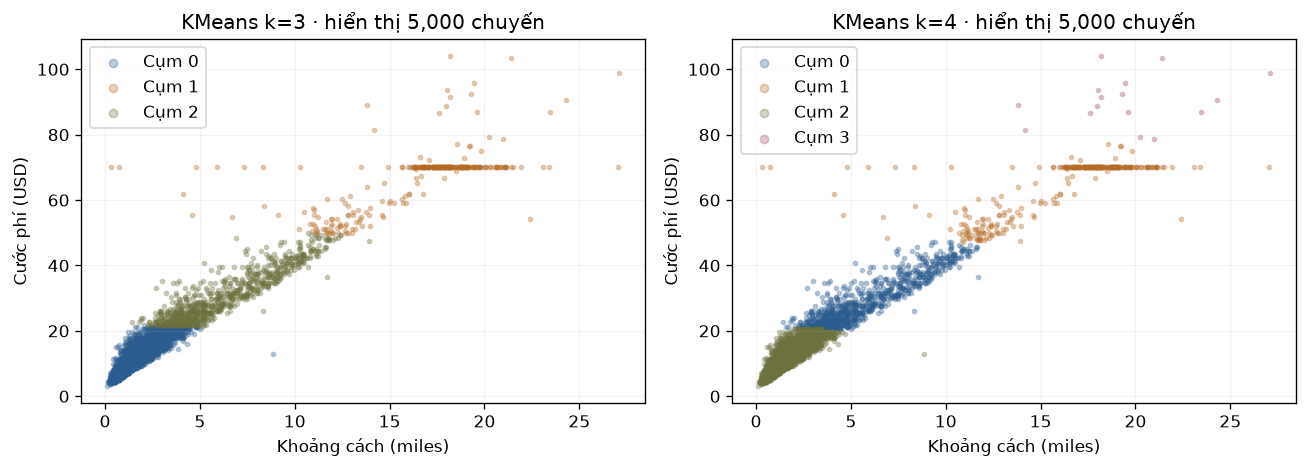

In [10]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':120})
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,k,clustered in [(axes[0],3,df_clustered),(axes[1],4,clustered4)]:
    points=clustered.select('trip_distance','fare_amount','cluster_id').sample(False,0.005,seed=42).orderBy(F.rand(seed=43)).limit(5000).toPandas()
    colors=['#2b5c8f','#b56b24','#6d713d','#a24d75']
    for cluster in sorted(points.cluster_id.unique()):
        group=points[points.cluster_id==cluster]
        ax.scatter(group.trip_distance,group.fare_amount,s=6,alpha=0.3,color=colors[int(cluster)],label=f'Cụm {cluster}')
    ax.set(title=f'KMeans k={k} · hiển thị {len(points):,} chuyến',xlabel='Khoảng cách (miles)',ylabel='Cước phí (USD)')
    ax.legend(markerscale=2);ax.grid(alpha=0.15)
plt.tight_layout();plt.show()

5 - Phân loại bằng Logistic Regression (Supervised Learning)

In [11]:
from pyspark.ml.classification import LogisticRegression
# train_data và test_data dùng chung split thô cố định ở bước 3.
lr_model = LogisticRegression(featuresCol='features',labelCol='high_tip',maxIter=60).fit(train_data)
predictions_lr = lr_model.transform(test_data)
predictions_lr.select('features','high_tip','prediction','probability').show(5,truncate=False)

+----------------------------------------------------------------------------------------------------------------------------------------------+--------+----------+----------------------------------------+
|features                                                                                                                                      |high_tip|prediction|probability                             |
+----------------------------------------------------------------------------------------------------------------------------------------------+--------+----------+----------------------------------------+
|[-0.4124887064683445,-0.6160036837117123,0.7136778756191663,-2.477739717835006,1.5313158520206986,0.9326924151105366,-0.07660676825839934]    |1       |1.0       |[0.23145924943515914,0.7685407505648408]|
|[-0.4850964218783446,-0.6160036837117123,-0.4243563436238901,-2.477739717835006,-1.3761084426837054,-0.39942598780782146,-0.07660676825839934]|1       |1.0       |[0.249087836

Bài tập 4: Trích xuất mảng hệ số lr_model.coefficients và biến hệ số chặn lr_model.intercept.
Ghép tương ứng các hệ số đó với danh sách cột feature_cols để xác định yếu tố nào làm tăng khả năng nhận tiền Tip cao nhất.

In [12]:
coefficients = lr_model.coefficients.toArray()
intercept = float(lr_model.intercept)
print('Intercept:',intercept)
coefficient_rows = sorted(zip(feature_cols, coefficients),key=lambda x:float(x[1]),reverse=True)
for name, beta in coefficient_rows:
    print(f'{name:18s}: beta={beta:+.6f}, odds ratio/1 SD={math.exp(float(beta)):.6f}')
positive = [(name,beta) for name,beta in coefficient_rows if beta > 0]
print('Hệ số dương lớn nhất:',positive[0] if positive else 'Không có hệ số dương')

Intercept: 1.0970736439089472
trip_distance     : beta=+0.220975, odds ratio/1 SD=1.247292
pickup_hour       : beta=+0.053653, odds ratio/1 SD=1.055118
DOLocationID      : beta=+0.027878, odds ratio/1 SD=1.028270
passenger_count   : beta=+0.011920, odds ratio/1 SD=1.011991
PULocationID      : beta=+0.010270, odds ratio/1 SD=1.010323
fare_amount       : beta=-0.395646, odds ratio/1 SD=0.673245
RatecodeID        : beta=-0.432706, odds ratio/1 SD=0.648751
Hệ số dương lớn nhất: ('trip_distance', np.float64(0.22097465286080917))


Các hệ số trên ứng với vector **đã chuẩn hóa**: tăng 1 độ lệch chuẩn của biến, giữ các biến khác cố định, làm odds nhân `exp(beta)`.
`beta` dương lớn nhất biểu thị mức tăng log-odds mạnh nhất theo thang này; không có nghĩa chắc chắn tip cao hoặc quan hệ nhân quả.
Mã khu vực và mã giá là biến phân loại, nên xem chúng như số thứ tự ở mô hình cơ sở chỉ là giới hạn của bài thực hành; bài 9 xử lý lại bằng one-hot.

**Kết quả đã lưu:** `trip_distance` có hệ số dương lớn nhất, β ≈ 0,220975, odds ratio ≈ 1,247292 cho mỗi 1 độ lệch chuẩn, giữ các biến khác cố định.

6 - Phân loại bằng Decision Tree (Supervised Learning)

In [13]:
from pyspark.ml.classification import DecisionTreeClassifier

# Khởi tạo mô hình Cây quyết định (Decision Tree)
dt = DecisionTreeClassifier(
    featuresCol="features", 
    labelCol="high_tip", 
    maxDepth=5, 
    seed=42
)

# Huấn luyện mô hình
dt_model = dt.fit(train_data)

# Dự đoán trên tập Test
predictions_dt = dt_model.transform(test_data)
predictions_dt.select("high_tip", "prediction", "probability").show(5)

+--------+----------+--------------------+
|high_tip|prediction|         probability|
+--------+----------+--------------------+
|       1|       1.0|[0.18805541173114...|
|       1|       1.0|[0.21122282375182...|
|       1|       1.0|[0.34647160875885...|
|       1|       1.0|[0.34647160875885...|
|       1|       1.0|[0.24886361355618...|
+--------+----------+--------------------+
only showing top 5 rows


Bài tập 5: In cấu trúc logic cây phân nhánh bằng câu lệnh print(dt_model.toDebugString).
Thay đổi độ sâu của cây maxDepth = 10 và tiến hành huấn luyện lại.

In [14]:
print(dt_model.toDebugString)
dt10_model = DecisionTreeClassifier(featuresCol='features',labelCol='high_tip',maxDepth=10,seed=42).fit(train_data)
predictions_dt10 = dt10_model.transform(test_data)
print('Cây maxDepth=10: số nút =',dt10_model.numNodes,'; độ sâu thực tế =',dt10_model.depth)

DecisionTreeClassificationModel: uid=DecisionTreeClassifier_dfe8333b6d06, depth=5, numNodes=17, numClasses=2, numFeatures=7
  If (feature 6 <= 7.388938342159362)
   If (feature 1 <= -0.5642327255556273)
    If (feature 3 <= -1.0076451305045793)
     If (feature 4 <= -0.0962097042540493)
      If (feature 6 <= 0.362542944119116)
       Predict: 1.0
      Else (feature 6 > 0.362542944119116)
       Predict: 0.0
     Else (feature 4 > -0.0962097042540493)
      Predict: 1.0
    Else (feature 3 > -1.0076451305045793)
     Predict: 1.0
   Else (feature 1 > -0.5642327255556273)
    If (feature 1 <= -0.19860033357827733)
     Predict: 1.0
    Else (feature 1 > -0.19860033357827733)
     If (feature 3 <= -1.0076451305045793)
      If (feature 6 <= 0.362542944119116)
       Predict: 1.0
      Else (feature 6 > 0.362542944119116)
       Predict: 0.0
     Else (feature 3 > -1.0076451305045793)
      Predict: 1.0
  Else (feature 6 > 7.388938342159362)
   Predict: 0.0



Cây maxDepth=10: số nút = 301 ; độ sâu thực tế = 10


7 - Đánh giá & So sánh mô hình (Model Evaluation)

In [15]:
# Dùng xác suất lớp 1: rawPrediction của cây là số mẫu từng lớp trong lá.
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# Evaluator cho chỉ số AUC (Area Under ROC)
evaluator_auc = BinaryClassificationEvaluator(labelCol="high_tip", rawPredictionCol="probability", metricName="areaUnderROC")

# Evaluator cho chỉ số Accuracy, Precision, Recall
evaluator_acc = MulticlassClassificationEvaluator(labelCol="high_tip", metricName="accuracy")
evaluator_prec = MulticlassClassificationEvaluator(labelCol="high_tip", metricName="precisionByLabel")

# Đánh giá mô hình Logistic Regression
auc_lr = evaluator_auc.evaluate(predictions_lr)
acc_lr = evaluator_acc.evaluate(predictions_lr)

# Đánh giá mô hình Decision Tree
auc_dt = evaluator_auc.evaluate(predictions_dt)
acc_dt = evaluator_acc.evaluate(predictions_dt)

print("============ KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ============")
print(f"Logistic Regression -> AUC-ROC: {auc_lr:.4f} | Accuracy: {acc_lr:.4f}")
print(f"Decision Tree       -> AUC-ROC: {auc_dt:.4f} | Accuracy: {acc_dt:.4f}")

============ KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ============
Logistic Regression -> AUC-ROC: 0.5847 | Accuracy: 0.7548
Decision Tree       -> AUC-ROC: 0.5897 | Accuracy: 0.7558


Bài tập 6: Sử dụng PySpark SQL để lập Confusion Matrix (Ma trận nhầm lẫn) giữa high_tip và prediction cho kết quả dự đoán của mô hình Decision Tree.
Dựa trên chỉ số AUC-ROC, cho biết mô hình nào hoạt động tốt hơn trên tập dữ liệu NYC Taxi này.

In [16]:
predictions_dt.createOrReplaceTempView('dt_predictions')
spark.sql("""
SELECT CAST(high_tip AS INT) AS actual,
       SUM(CASE WHEN prediction=0 THEN 1 ELSE 0 END) AS predicted_0,
       SUM(CASE WHEN prediction=1 THEN 1 ELSE 0 END) AS predicted_1
FROM dt_predictions
GROUP BY high_tip ORDER BY actual
""").show()
print('Hàng actual=0: TN, FP; hàng actual=1: FN, TP.')
for name,pred in [('LR',predictions_lr),('DT depth=5',predictions_dt),('DT depth=10',predictions_dt10)]:
    print(name,'AUC-ROC =',evaluator_auc.evaluate(pred),'Accuracy =',evaluator_acc.evaluate(pred))
if abs(auc_lr-auc_dt) <= 1e-6:
    print('LR và DT có AUC-ROC tương đương trong sai số 1e-6.')
else:
    print('Mô hình có AUC-ROC cao hơn trên tập test hiện tại:', 'LR' if auc_lr > auc_dt else 'DT')

+------+-----------+-----------+
|actual|predicted_0|predicted_1|
+------+-----------+-----------+
|     0|       4422|     220994|
|     1|        141|     679857|
+------+-----------+-----------+

Hàng actual=0: TN, FP; hàng actual=1: FN, TP.


LR AUC-ROC = 0.5846627368507885 Accuracy = 0.7547652234226553


DT depth=5 AUC-ROC = 0.5897446647712172 Accuracy = 0.7557636617061366


DT depth=10 AUC-ROC = 0.6007301188943015 Accuracy = 0.7558045269898632
Mô hình có AUC-ROC cao hơn trên tập test hiện tại: DT


AUC-ROC cao hơn là kết quả quan sát trên một lần chia tập, chưa phải bằng chứng chênh lệch có ý nghĩa thống kê. Cây sâu hơn có thể khớp train tốt hơn nhưng tăng nguy cơ quá khớp; so sánh trên cùng test.

ROC-AUC và PR-AUC cùng dùng `probability` làm điểm số. `rawPrediction` của cây là số mẫu từng lớp ở lá, nên dùng số đếm lớp 1 có thể xếp hạng khác xác suất lớp 1. Kiểm thử `test_ml_metrics.py` kiểm tra trường hợp này.

### Accuracy có hơn cách luôn đoán tip cao không?
Dùng tỷ lệ lớp ngay trên cùng tập test làm baseline. Báo cáo recall và F1 cho cả
hai lớp, macro-F1 và balanced accuracy; cách này cho thấy lớp tip thấp có bị bỏ qua
dù accuracy tổng thể khá cao hay không. Định nghĩa lớp 1 vẫn là `tip/fare > 20%`.

In [17]:
def binary_report(frame):
    row = frame.agg(*[
        F.sum(F.when((F.col('high_tip')==actual)&(F.col('prediction')==predicted),1).otherwise(0)).alias(key)
        for key,actual,predicted in [('TN',0,0),('FP',0,1),('FN',1,0),('TP',1,1)]
    ]).first()
    tn,fp,fn,tp = [int(row[k] or 0) for k in ['TN','FP','FN','TP']]
    n = tn+fp+fn+tp
    div = lambda a,b: a/b if b else 0.0
    recall0,recall1 = div(tn,tn+fp),div(tp,tp+fn)
    f10,f11 = div(2*tn,2*tn+fp+fn),div(2*tp,2*tp+fp+fn)
    return dict(TN=tn,FP=fp,FN=fn,TP=tp,n=n,accuracy=div(tn+tp,n),
        precision_0=div(tn,tn+fn),recall_0=recall0,F1_0=f10,
        precision_1=div(tp,tp+fp),recall_1=recall1,F1_1=f11,
        balanced_accuracy=(recall0+recall1)/2,macro_F1=(f10+f11)/2)

# Nhãn phổ biến được xác định từ train, sau đó mới đánh giá trên test.
majority_label = int(raw_train.groupBy('high_tip').count().orderBy(F.desc('count'),'high_tip').first().high_tip)
majority_predictions = raw_test.withColumn('prediction',F.lit(float(majority_label)))
majority_report = binary_report(majority_predictions)
class_reports = {'Luôn đoán lớp train phổ biến':majority_report}
for name,pred in [('LR cơ sở',predictions_lr),('DT depth=5',predictions_dt),('DT depth=10',predictions_dt10)]:
    class_reports[name] = binary_report(pred)
report_fields = ['accuracy','recall_0','recall_1','F1_0','F1_1','balanced_accuracy','macro_F1']
def show_class_reports(reports):
    spark.createDataFrame([(name,)+tuple(float(r[k]) for k in report_fields) for name,r in reports.items()],
        ['model']+report_fields).show(truncate=False)
show_class_reports(class_reports)
tree_report = class_reports['DT depth=5']
assert tree_report['n'] == raw_test.count()
assert abs(tree_report['accuracy']-acc_dt) < 1e-12
print(f'Baseline chọn lớp {majority_label}: accuracy={majority_report["accuracy"]:.4%}.')
print(f'DT depth=5 hơn baseline {(tree_report["accuracy"]-majority_report["accuracy"])*100:.3f} điểm phần trăm; '
      f'nhận đúng lớp 0: {tree_report["TN"]:,}/{tree_report["TN"]+tree_report["FP"]:,} '
      f'({tree_report["recall_0"]:.2%}).')
print('ROC-AUC gần 0.6 cùng recall lớp 0 thấp cho thấy khả năng phân biệt còn hạn chế; '
      'accuracy khoảng 75% chưa đủ để gọi mô hình tốt.')

+----------------------------+------------------+--------------------+------------------+-------------------+------------------+------------------+-------------------+
|model                       |accuracy          |recall_0            |recall_1          |F1_0               |F1_1              |balanced_accuracy |macro_F1           |
+----------------------------+------------------+--------------------+------------------+-------------------+------------------+------------------+-------------------+
|Luôn đoán lớp train phổ biến|0.7510354379322608|0.0                 |1.0               |0.0                |0.8578186616475717|0.5               |0.42890933082378585|
|LR cơ sở                    |0.7547652234226553|0.02402668843382901 |0.9970014617690052|0.04651502333910191|0.8592870401411445|0.5105140751014171|0.45290103174012325|
|DT depth=5                  |0.7557636617061366|0.019617063562480035|0.9997926464489602|0.03845568508429031|0.8601163045932914|0.50970485500572  |0.44928599483

8 - Xây dựng quy trình tự động với PySpark Pipeline

In [18]:
from pyspark.ml import Pipeline
stage_assembler = VectorAssembler(inputCols=feature_cols,outputCol='raw_features')
stage_scaler = StandardScaler(inputCol='raw_features',outputCol='features',withStd=True,withMean=True)
stage_dt = DecisionTreeClassifier(featuresCol='features',labelCol='high_tip',maxDepth=5,seed=42)
pipeline = Pipeline(stages=[stage_assembler,stage_scaler,stage_dt])
# Tái sử dụng CHÍNH raw_train/raw_test cũ. Không chia lại tập.
pipeline_model = pipeline.fit(raw_train)
pipeline_predictions = pipeline_model.transform(raw_test)
pipeline_predictions.select('trip_distance','fare_amount','high_tip','prediction').show(5)

+-------------+-----------+--------+----------+
|trip_distance|fare_amount|high_tip|prediction|
+-------------+-----------+--------+----------+
|          1.6|        8.6|       1|       1.0|
|          1.3|        8.6|       1|       1.0|
|          9.1|       38.0|       1|       1.0|
|          3.4|       17.0|       1|       1.0|
|          1.6|       12.8|       1|       1.0|
+-------------+-----------+--------+----------+
only showing top 5 rows


Bài tập 7: Hãy thay thế giai đoạn stage_dt trong Pipeline bằng LogisticRegression và chạy lại quy trình thử nghiệm.

In [19]:
stage_lr = LogisticRegression(featuresCol='features',labelCol='high_tip',maxIter=60,regParam=0.01)
pipeline_lr = Pipeline(stages=[stage_assembler,stage_scaler,stage_lr])
pipeline_lr_model = pipeline_lr.fit(raw_train)
pipeline_lr_predictions = pipeline_lr_model.transform(raw_test)
print('Pipeline Logistic Regression, AUC-ROC:',evaluator_auc.evaluate(pipeline_lr_predictions))

Pipeline Logistic Regression, AUC-ROC: 0.5829949542883147


9 - Lưu trữ & Tái sử dụng mô hình (Model Persistence)

In [20]:
from pyspark.ml import PipelineModel
model_directory = './loi_giai/models/nyc_taxi_dt_pipeline'
pipeline_model.write().overwrite().save(model_directory)
loaded_model = PipelineModel.load(model_directory)
print('Đã lưu và nạp lại pipeline Decision Tree:',model_directory)
loaded_model.transform(raw_test.limit(5)).select('high_tip','prediction','probability').show(truncate=False)

Đã lưu và nạp lại pipeline Decision Tree: ./loi_giai/models/nyc_taxi_dt_pipeline
+--------+----------+----------------------------------------+
|high_tip|prediction|probability                             |
+--------+----------+----------------------------------------+
|1       |1.0       |[0.1880554117311411,0.811944588268859]  |
|1       |1.0       |[0.21122282375182608,0.7887771762481739]|
|1       |1.0       |[0.3464716087588503,0.6535283912411497] |
|1       |1.0       |[0.3464716087588503,0.6535283912411497] |
|1       |1.0       |[0.24886361355618056,0.7511363864438194]|
+--------+----------+----------------------------------------+



Bài tập 8: Tạo một PySpark DataFrame mới chứa thông tin của 2 chuyến taxi thực tế giả định:
+ Chuyến 1: trip_distance=1.2, fare_amount=8.5, passenger_count=1, pickup_hour=14, PULocationID=138, DOLocationID=263
+ Chuyến 2: trip_distance=15.5, fare_amount=65.0, passenger_count=2, pickup_hour=20, PULocationID=132, DOLocationID=142

Dùng loaded_model dự đoán xem 2 chuyến đi này có khả năng thuộc nhóm high_tip hay không.

In [21]:
# RatecodeID chưa được đề cung cấp: giả định giá chuẩn = 1 cho cả hai chuyến.
new_trips = spark.createDataFrame([
    (1,1.2,8.5,1.,14.,138.,263.,1.),
    (2,15.5,65.0,2.,20.,132.,142.,1.)
], ['trip_id','trip_distance','fare_amount','passenger_count','pickup_hour','PULocationID','DOLocationID','RatecodeID'])
from pyspark.ml.functions import vector_to_array
(loaded_model.transform(new_trips).withColumn('p_high_tip',vector_to_array('probability')[1])
    .select('trip_id','trip_distance','fare_amount','RatecodeID','prediction','p_high_tip').show(truncate=False))

+-------+-------------+-----------+----------+----------+------------------+
|trip_id|trip_distance|fare_amount|RatecodeID|prediction|p_high_tip        |
+-------+-------------+-----------+----------+----------+------------------+
|1      |1.2          |8.5        |1.0       |1.0       |0.8335564649690782|
|2      |15.5         |65.0       |1.0       |1.0       |0.7062143655518203|
+-------+-------------+-----------+----------+----------+------------------+



Dự đoán dùng pipeline đã lưu ở bước 9 (DT depth=5); `p_high_tip` là xác suất mô hình ước lượng, nhãn mặc định theo ngưỡng 0.5. Kết quả thay đổi khi đổi dữ liệu hoặc mã giá giả định.

Bài tập 9: Hãy tìm cách cải tiến để các mô hình huấn luyện tốt hơn. So sánh với kết quả các mô hình trước đây và phân tích lý do vì sao cải tiến có tác dụng.

### Lời giải bài 9 — Cải tiến và so sánh công bằng
1. One-hot mã vùng/mã giá để bỏ giả định thứ tự, giờ dạng sin/cos để giờ 23 gần giờ 0; log khoảng cách/cước giảm lệch phải.
2. Tách validation **từ raw_train**, chọn regularization trên validation bằng PR-AUC; không chọn tham số bằng test.
3. Fit lại pipeline được chọn trên toàn bộ raw_train, đánh giá cùng raw_test với LR/DT cũ. Cải tiến có thể có hoặc không; code báo chênh lệch thực tế, không mặc định kết quả tốt hơn.

In [22]:
from pyspark.ml.feature import SQLTransformer, StringIndexer, OneHotEncoder
from pyspark.ml.evaluation import BinaryClassificationEvaluator
feature_sql = SQLTransformer(statement="""
SELECT *, LOG(1 + trip_distance) AS log_distance, LOG(1 + fare_amount) AS log_fare,
 SIN(2 * PI() * pickup_hour / 24) AS hour_sin,
 COS(2 * PI() * pickup_hour / 24) AS hour_cos,
 CAST(PULocationID AS STRING) AS pu_cat,
 CAST(DOLocationID AS STRING) AS do_cat,
 CAST(RatecodeID AS STRING) AS rate_cat FROM __THIS__
""")
indexer = StringIndexer(inputCols=['pu_cat','do_cat','rate_cat'],outputCols=['pu_idx','do_idx','rate_idx'],handleInvalid='keep')
encoder = OneHotEncoder(inputCols=['pu_idx','do_idx','rate_idx'],outputCols=['pu_vec','do_vec','rate_vec'],handleInvalid='keep')
new_assembler = VectorAssembler(inputCols=['log_distance','log_fare','passenger_count','hour_sin','hour_cos','pu_vec','do_vec','rate_vec'],outputCol='improved_features')
inner_train, validation = raw_train.randomSplit([0.8,0.2],seed=2026)
inner_train=inner_train.cache();validation=validation.cache()
pr_evaluator = BinaryClassificationEvaluator(labelCol='high_tip',rawPredictionCol='probability',metricName='areaUnderPR')
trials=[]
for reg in [0.001,0.01,0.1]:
    estimator=LogisticRegression(featuresCol='improved_features',labelCol='high_tip',maxIter=80,regParam=reg)
    candidate=Pipeline(stages=[feature_sql,indexer,encoder,new_assembler,estimator])
    model=candidate.fit(inner_train)
    score=pr_evaluator.evaluate(model.transform(validation))
    trials.append((reg,score,candidate))
    print(f'regParam={reg}: validation PR-AUC={score:.6f}')
best_reg, best_score, best_pipeline = max(trials,key=lambda x:x[1])
improved_model=best_pipeline.fit(raw_train)
improved_predictions=improved_model.transform(raw_test)
comparison=[]
for name,pred in [('LR cơ sở',predictions_lr),('DT depth=5',predictions_dt),('DT depth=10',predictions_dt10),('LR cải tiến',improved_predictions)]:
    comparison.append((name,float(evaluator_auc.evaluate(pred)),float(pr_evaluator.evaluate(pred)),float(evaluator_acc.evaluate(pred))))
comparison_df=spark.createDataFrame(comparison,['model','ROC_AUC','PR_AUC','Accuracy'])
comparison_df.show(truncate=False)
base_pr=next(x[2] for x in comparison if x[0]=='LR cơ sở')
new_pr=next(x[2] for x in comparison if x[0]=='LR cải tiến')
print(f'Chọn regParam={best_reg} bằng validation; thay đổi test PR-AUC so LR cơ sở: {new_pr-base_pr:+.6f}')
print('Các thay đổi có ích trên mẫu hiện tại.' if new_pr > base_pr else 'Chưa có cải thiện PR-AUC trên mẫu hiện tại; cần kiểm tra thêm dữ liệu và tham số.')
improved_model.write().overwrite().save('./loi_giai/models/nyc_taxi_improved_pipeline')
inner_train.unpersist();validation.unpersist()

regParam=0.001: validation PR-AUC=0.810888


regParam=0.01: validation PR-AUC=0.810450


regParam=0.1: validation PR-AUC=0.809028


+-----------+------------------+------------------+------------------+
|model      |ROC_AUC           |PR_AUC            |Accuracy          |
+-----------+------------------+------------------+------------------+
|LR cơ sở   |0.5846622186668032|0.7996458790172452|0.7547652234226553|
|DT depth=5 |0.5897446647712172|0.8044316409597622|0.7557636617061366|
|DT depth=10|0.6007301188943015|0.8090349249821885|0.7558045269898632|
|LR cải tiến|0.6082023624724918|0.8111614130686374|0.7561678966748913|
+-----------+------------------+------------------+------------------+

Chọn regParam=0.001 bằng validation; thay đổi test PR-AUC so LR cơ sở: +0.011516
Các thay đổi có ích trên mẫu hiện tại.


DataFrame[VendorID: bigint, tpep_pickup_datetime: timestamp_ntz, tpep_dropoff_datetime: timestamp_ntz, passenger_count: double, trip_distance: double, RatecodeID: double, store_and_fwd_flag: string, PULocationID: bigint, DOLocationID: bigint, payment_type: bigint, fare_amount: double, extra: double, mta_tax: double, tip_amount: double, tolls_amount: double, improvement_surcharge: double, total_amount: double, congestion_surcharge: double, airport_fee: double, trip_duration_min: double, speed_mph: double, pickup_date: date, pickup_hour: int, high_tip: int]

### Kiểm tra từng nhóm thay đổi trên validation
Để xem mức tăng đến từ đâu, huấn luyện thêm hai cấu hình trên **cùng inner_train**,
so trên **cùng validation**, giữ `regParam=0.001` và `maxIter=80`.
A dùng mã vùng/mã giá dạng số; B thay bằng one-hot; C thêm log và giờ sin/cos.
C đã có trong các thử nghiệm ở trên, nên dùng lại điểm validation đã tính.
Đây là kiểm tra theo nhóm: chưa tách được đóng góp riêng của log và sin/cos,
và không cộng các chênh lệch như những tác động độc lập.

In [23]:
ablation = []
# Cache đã nhả ở cell trên; khôi phục cùng DataFrame, cùng split trước khi fit.
inner_train = inner_train.cache(); validation = validation.cache()
numeric_pipeline = Pipeline(stages=[
    VectorAssembler(inputCols=feature_cols,outputCol='ablation_raw'),
    StandardScaler(inputCol='ablation_raw',outputCol='ablation_features',withMean=True,withStd=True),
    LogisticRegression(featuresCol='ablation_features',labelCol='high_tip',regParam=0.001,maxIter=80)])
numeric_fit = numeric_pipeline.fit(inner_train)
ablation.append(('A · Mã dạng số',float(pr_evaluator.evaluate(numeric_fit.transform(validation)))))
onehot_assembler = VectorAssembler(inputCols=['trip_distance','fare_amount','passenger_count','pickup_hour',
    'pu_vec','do_vec','rate_vec'],outputCol='ablation_features')
onehot_pipeline = Pipeline(stages=[feature_sql,indexer,encoder,onehot_assembler,
    LogisticRegression(featuresCol='ablation_features',labelCol='high_tip',regParam=0.001,maxIter=80)])
onehot_fit = onehot_pipeline.fit(inner_train)
ablation.append(('B · One-hot',float(pr_evaluator.evaluate(onehot_fit.transform(validation)))))
full_validation = next(score for reg,score,_ in trials if reg==0.001)
ablation.append(('C · One-hot + log + sin/cos',float(full_validation)))
spark.createDataFrame(ablation,['configuration','validation_PR_AUC']).show(truncate=False)
for (before,a),(after,b) in zip(ablation,ablation[1:]):
    print(f'{before} → {after}: validation PR-AUC thay đổi {b-a:+.6f}.')
print('Giữ nguyên mô hình cuối và test đã đánh giá; không chọn lại cấu hình theo điểm test.')
class_reports['LR cải tiến'] = binary_report(improved_predictions)
show_class_reports(class_reports)
test_prevalence = raw_test.agg(F.avg('high_tip')).first()[0]
print(f'Tỷ lệ lớp 1 trên test={test_prevalence:.4%}; đây là mức precision tham chiếu '
      'của xếp hạng ngẫu nhiên, không phải bằng chứng PR-AUC gần 0.8 là rất tốt.')
print(f'LR cải tiến hơn majority baseline '
      f'{(class_reports["LR cải tiến"]["accuracy"]-majority_report["accuracy"])*100:.3f} điểm phần trăm accuracy.')
inner_train.unpersist(); validation.unpersist()

+---------------------------+------------------+
|configuration              |validation_PR_AUC |
+---------------------------+------------------+
|A · Mã dạng số             |0.7986792252297752|
|B · One-hot                |0.8048820216914588|
|C · One-hot + log + sin/cos|0.8108883614301367|
+---------------------------+------------------+

A · Mã dạng số → B · One-hot: validation PR-AUC thay đổi +0.006203.
B · One-hot → C · One-hot + log + sin/cos: validation PR-AUC thay đổi +0.006006.
Giữ nguyên mô hình cuối và test đã đánh giá; không chọn lại cấu hình theo điểm test.


+----------------------------+------------------+--------------------+------------------+-------------------+------------------+------------------+-------------------+
|model                       |accuracy          |recall_0            |recall_1          |F1_0               |F1_1              |balanced_accuracy |macro_F1           |
+----------------------------+------------------+--------------------+------------------+-------------------+------------------+------------------+-------------------+
|Luôn đoán lớp train phổ biến|0.7510354379322608|0.0                 |1.0               |0.0                |0.8578186616475717|0.5               |0.42890933082378585|
|LR cơ sở                    |0.7547652234226553|0.02402668843382901 |0.9970014617690052|0.04651502333910191|0.8592870401411445|0.5105140751014171|0.45290103174012325|
|DT depth=5                  |0.7557636617061366|0.019617063562480035|0.9997926464489602|0.03845568508429031|0.8601163045932914|0.50970485500572  |0.44928599483

DataFrame[VendorID: bigint, tpep_pickup_datetime: timestamp_ntz, tpep_dropoff_datetime: timestamp_ntz, passenger_count: double, trip_distance: double, RatecodeID: double, store_and_fwd_flag: string, PULocationID: bigint, DOLocationID: bigint, payment_type: bigint, fare_amount: double, extra: double, mta_tax: double, tip_amount: double, tolls_amount: double, improvement_surcharge: double, total_amount: double, congestion_surcharge: double, airport_fee: double, trip_duration_min: double, speed_mph: double, pickup_date: date, pickup_hour: int, high_tip: int]

**Kết quả kiểm tra nhóm đặc trưng:** validation PR-AUC tăng từ 0,798679 (mã dạng số) lên 0,804882 (one-hot), rồi 0,810888 (thêm log và sin/cos). Hai bước tăng lần lượt khoảng 0,006203 và 0,006006, cùng split và regularization. Bảng này hỗ trợ cách giải thích cải tiến bằng dữ liệu; chưa tách được tác động riêng của log và sin/cos.

Trên test, LR cải tiến có balanced accuracy **0,513857** và macro-F1 **0,459939**. Recall lớp tip thấp tăng từ **2,4027%** của LR cơ sở lên **3,1236%**, nhưng vẫn bỏ sót phần lớn lớp này. Vì thế mức tăng AUC chưa biến mô hình thành công cụ dự đoán tốt cho cả hai nhóm. Nếu mục tiêu là phát hiện nhóm tip thấp, cần xác định chi phí sai và chọn ngưỡng bằng validation. Chia theo thời gian và thử thêm nhiều seed là bước kiểm tra tiếp theo.

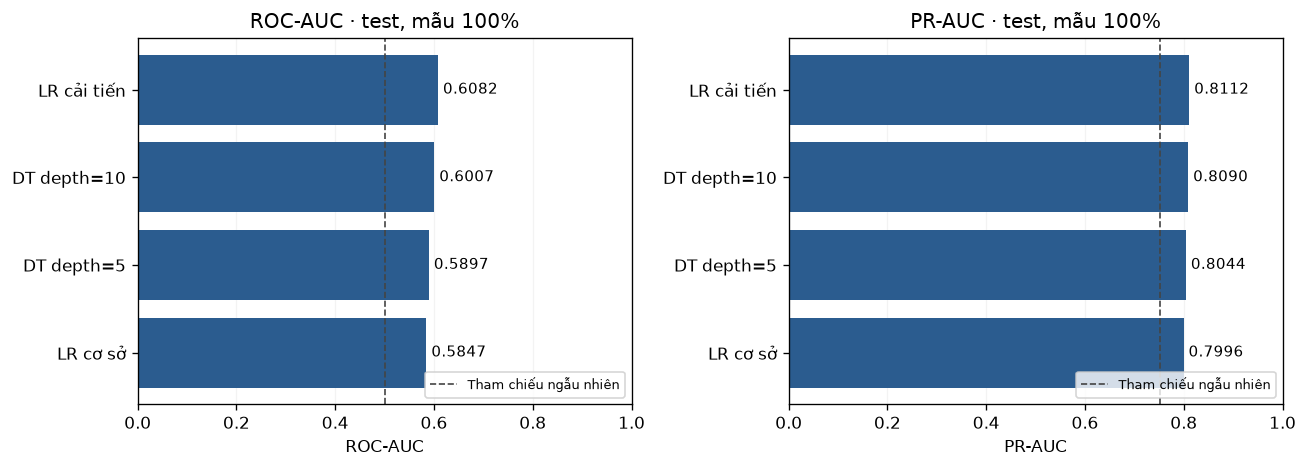

In [24]:
# Các điểm số đã tính trên cùng tập test; cột bắt đầu từ 0.
fig,axes=plt.subplots(1,2,figsize=(11,4))
names=[x[0] for x in comparison]
for ax,col,title in [(axes[0],1,'ROC-AUC'),(axes[1],2,'PR-AUC')]:
    bars=ax.barh(names,[x[col] for x in comparison],color='#2b5c8f')
    ax.set(xlim=(0,1),xlabel=title,title=f'{title} · test, mẫu {ML_FRACTION:.0%}')
    ax.bar_label(bars,fmt='%.4f',padding=3,fontsize=9)
    reference = 0.5 if col==1 else test_prevalence
    ax.axvline(reference,color='#444444',linestyle='--',linewidth=1,label='Tham chiếu ngẫu nhiên')
    ax.legend(loc='lower right',fontsize=8)
    ax.grid(axis='x',alpha=0.15);ax.set_axisbelow(True)
plt.tight_layout();plt.show()

**Giải thích:** One-hot cho phép học mức tip riêng của từng vùng/mã giá, thay vì giả định mã lớn hơn có tác động tuyến tính mạnh hơn.
Sin/cos thể hiện chu kỳ 24 giờ; log giảm ảnh hưởng ngoại lệ; regularization hạn chế hệ số quá lớn.
Nếu bảng so sánh không tăng điểm, các cơ chế này chưa chứng minh được hiệu quả trên lần chia hiện tại. Có thể thử thêm cây tổ hợp hoặc chia theo thời gian, nhưng phải giữ tập kiểm tra độc lập.
Các đặc trưng cước/quãng đường phù hợp dự đoán khi chuyến kết thúc, không có sẵn đầy đủ khi vừa đặt xe.

In [25]:
# Lưu các số đã tính để đối chiếu phần tóm tắt sau khi chạy lại.
import json
ml_run_report = dict(ml_fraction=ML_FRACTION,train_n=raw_train.count(),test_n=raw_test.count(),
    majority_label=majority_label,test_prevalence=test_prevalence,class_reports=class_reports,
    comparison=[dict(model=r[0],ROC_AUC=r[1],PR_AUC=r[2],accuracy=r[3]) for r in comparison],
    ablation=[dict(configuration=name,validation_PR_AUC=value) for name,value in ablation],
    best_reg=best_reg,silhouette_k3=silhouette3,silhouette_k4=silhouette4)
(ROOT/'.work').mkdir(exist_ok=True)
(ROOT/'.work'/'ml_review_results.json').write_text(json.dumps(ml_run_report,ensure_ascii=False,indent=2),encoding='utf-8');


In [26]:
spark.stop()